# Klasifikasi Data Citra Tulisan Tangan — Dataset MLE

**Tugas:** klasifikasi citra tulisan tangan (identifikasi penulis) menggunakan:
1. **Ekstraksi fitur GLCM** + 2 classifier klasik: **SVM (RBF)** dan **Random Forest**
2. **2 arsitektur Deep Learning**: **CNN sederhana (dari nol)** dan **ResNet-18 (transfer learning ImageNet)**

Setiap metode dievaluasi dengan **5 eksperimen** menggunakan *Stratified 5-Fold Cross Validation* (pembagian fold yang sama untuk semua metode),
dengan metrik **Precision, Recall, Akurasi, F1-Score** (rata-rata *macro*) dan **waktu pelatihan**. Waktu ekstraksi fitur GLCM juga dicatat.

| Anggota | NIM | Nama | Tugas yang Dikerjakan |
|---|---|---|---|
| 1 | ... | ... | ... |
| 2 | ... | ... | ... |
| 3 | ... | ... | ... |

## 1. Import Library & Konfigurasi

In [1]:
import os, glob, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from skimage.filters import threshold_otsu
from skimage.feature import graycomatrix, graycoprops

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)

DATA_DIR  = "data_raw/MLE"      # folder dataset: satu sub-folder per kelas (penulis)
RESULT_DIR = "hasil"
IMG_H, IMG_W = 128, 512          # ukuran citra setelah diseragamkan (tinggi x lebar)
N_SPLITS = 5                     # jumlah eksperimen (5-fold)
SEED = 42
os.makedirs(RESULT_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

C:\Users\adidtiya kurniawan\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.2.2+cu121 | Device: cuda NVIDIA GeForce RTX 3050 Ti Laptop GPU


## 2. Memuat Dataset

Jumlah citra : 2311
Jumlah kelas : 44
Citra per kelas: min=47, max=77, rata-rata=52.5


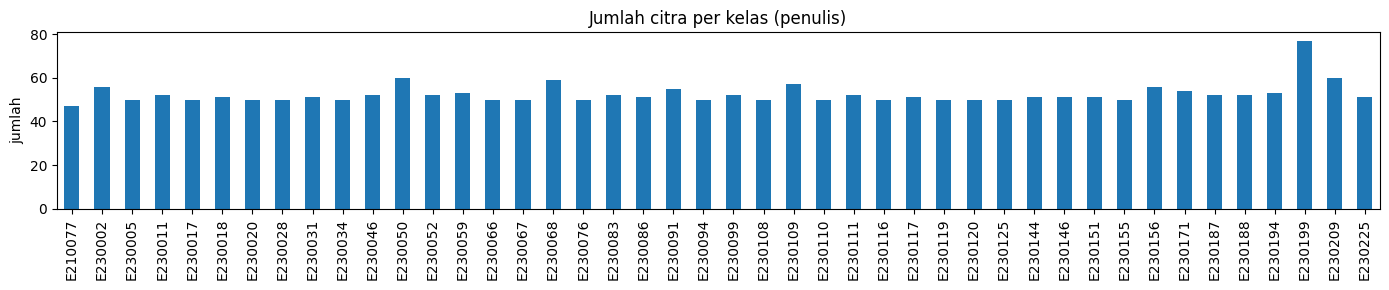

In [2]:
EXTS = (".jpg", ".jpeg", ".png", ".bmp")
classes = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
paths, labels = [], []
for c in classes:
    for f in sorted(os.listdir(os.path.join(DATA_DIR, c))):
        if f.lower().endswith(EXTS):
            paths.append(os.path.join(DATA_DIR, c, f)); labels.append(c)

le = LabelEncoder().fit(classes)
y = le.transform(labels)
n_classes = len(classes)
print(f"Jumlah citra : {len(paths)}")
print(f"Jumlah kelas : {n_classes}")

counts = pd.Series(labels).value_counts().sort_index()
print(f"Citra per kelas: min={counts.min()}, max={counts.max()}, rata-rata={counts.mean():.1f}")
counts.plot(kind="bar", figsize=(14, 3), title="Jumlah citra per kelas (penulis)"); plt.ylabel("jumlah"); plt.tight_layout(); plt.show()

## 3. Preprocessing

Citra berasal dari sumber yang berbeda-beda (RGB, grayscale, PNG transparan, ukuran 200 – 8000 px). Langkah preprocessing:
1. Konversi ke **grayscale** (citra transparan ditempel di atas latar putih).
2. **Crop** ke area tinta menggunakan threshold **Otsu**, sehingga margin kosong dibuang.
3. **Resize** ke ukuran seragam 128 × 512 piksel (rasio sesuai bentuk baris tulisan).

Preprocessing 2311 citra selesai dalam 7.83 detik -> shape (2311, 128, 512)


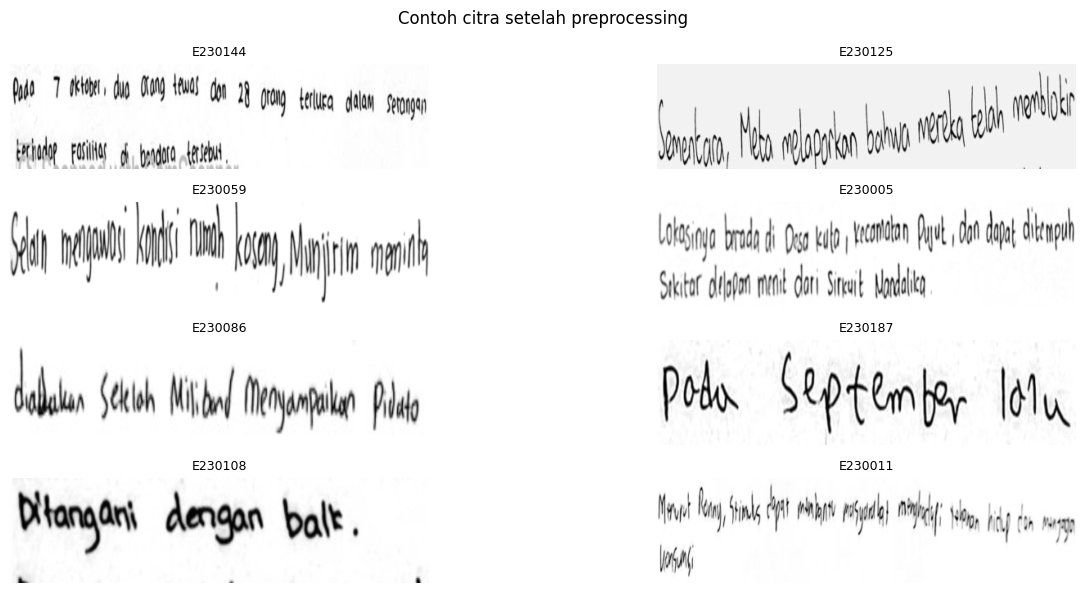

In [3]:
def load_gray(path):
    im = ImageOps.exif_transpose(Image.open(path))
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
        im = Image.alpha_composite(bg, im)
    return np.array(im.convert("L"))

def crop_ink(g, margin=8):
    try:
        ink = g < threshold_otsu(g)
    except ValueError:              # citra satu warna
        return g
    rows, cols = np.where(ink.any(1))[0], np.where(ink.any(0))[0]
    if len(rows) == 0:
        return g
    r0, r1 = max(rows[0] - margin, 0), min(rows[-1] + margin + 1, g.shape[0])
    c0, c1 = max(cols[0] - margin, 0), min(cols[-1] + margin + 1, g.shape[1])
    return g[r0:r1, c0:c1]

def preprocess(path):
    g = crop_ink(load_gray(path))
    return np.array(Image.fromarray(g).resize((IMG_W, IMG_H), Image.BILINEAR))

t0 = time.perf_counter()
X_img = np.stack([preprocess(p) for p in paths])     # (N, 128, 512) uint8
t_prep = time.perf_counter() - t0
print(f"Preprocessing {len(paths)} citra selesai dalam {t_prep:.2f} detik -> shape {X_img.shape}")

fig, axes = plt.subplots(4, 2, figsize=(14, 6))
for ax, i in zip(axes.ravel(), np.random.RandomState(1).choice(len(paths), 8, replace=False)):
    ax.imshow(X_img[i], cmap="gray"); ax.set_title(labels[i], fontsize=9); ax.axis("off")
plt.suptitle("Contoh citra setelah preprocessing"); plt.tight_layout(); plt.show()

## 4. Ekstraksi Fitur GLCM

*Gray Level Co-occurrence Matrix* dihitung dari citra yang dikuantisasi ke **32 level keabuan** dengan:
- jarak **d = 1, 2, 3, 5** piksel
- sudut **θ = 0°, 45°, 90°, 135°**

Dari setiap GLCM diambil 7 fitur: **contrast, dissimilarity, homogeneity, energy, correlation, ASM, entropy**
→ total 7 × 4 × 4 = **112 fitur** per citra. Waktu ekstraksi dicatat.

In [4]:
GLCM_LEVELS = 32
DISTANCES = [1, 2, 3, 5]
ANGLES = [0, np.pi/4, np.pi/2, 3*np.pi/4]
PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]

def glcm_features(img):
    q = (img.astype(np.uint16) * GLCM_LEVELS // 256).astype(np.uint8)
    P = graycomatrix(q, distances=DISTANCES, angles=ANGLES, levels=GLCM_LEVELS, symmetric=True, normed=True)
    feats = [graycoprops(P, p).ravel() for p in PROPS]
    entropy = -np.sum(P * np.log2(P + 1e-12), axis=(0, 1)).ravel()
    return np.concatenate(feats + [entropy])

feat_names = [f"{p}_d{d}_a{int(np.degrees(a))}" for p in PROPS + ["entropy"] for d in DISTANCES for a in ANGLES]

t0 = time.perf_counter()
X_glcm = np.stack([glcm_features(im) for im in X_img])
t_glcm = time.perf_counter() - t0

print(f"Shape fitur GLCM        : {X_glcm.shape}")
print(f"Waktu ekstraksi GLCM    : {t_glcm:.2f} detik (total {len(X_img)} citra)")
print(f"Rata-rata per citra     : {t_glcm / len(X_img) * 1000:.2f} ms")
pd.DataFrame(X_glcm, columns=feat_names).assign(kelas=labels).to_csv(f"{RESULT_DIR}/fitur_glcm.csv", index=False)
pd.DataFrame(X_glcm[:5], columns=feat_names).iloc[:, :10]

Shape fitur GLCM        : (2311, 112)
Waktu ekstraksi GLCM    : 5.20 detik (total 2311 citra)
Rata-rata per citra     : 2.25 ms


,contrast_d1_a0,contrast_d1_a45,contrast_d1_a90,contrast_d1_a135,contrast_d2_a0,contrast_d2_a45,contrast_d2_a90,contrast_d2_a135,contrast_d3_a0,contrast_d3_a45
0,13.9877,15.4141,5.2907,16.9961,25.2849,15.4141,13.0440,16.9961,25.4527,26.0914
1,16.2990,18.0216,5.9817,20.0581,30.8380,18.0216,15.5882,20.0581,32.2505,31.7385
2,25.1691,28.2831,11.1679,32.4309,47.7837,28.2831,26.7392,32.4309,49.4845,48.9952
3,25.4287,28.0480,10.4433,32.0034,47.0986,28.0480,26.0233,32.0034,47.6294,47.9235
4,23.7301,24.9441,5.0430,27.4644,44.8760,24.9441,15.2780,27.4644,45.2805,45.9702


## 5. Skenario Eksperimen

Digunakan **Stratified 5-Fold Cross Validation**: data dibagi menjadi 5 bagian dengan proporsi kelas yang sama.
Pada eksperimen ke-*k*, fold ke-*k* (±20%) menjadi data uji dan 4 fold lainnya (±80%) menjadi data latih.
Pembagian fold **sama** untuk keempat metode sehingga perbandingan adil.

Metrik: Precision, Recall dan F1-Score menggunakan rata-rata **macro** (rata-rata antar 44 kelas). Waktu pelatihan = waktu `fit` / training model pada data latih.

In [5]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(np.zeros(len(y)), y))
for k, (tr, te) in enumerate(FOLDS, 1):
    print(f"Eksperimen {k}: latih={len(tr)}, uji={len(te)}")

def evaluate(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"Precision": p, "Recall": r, "Akurasi": accuracy_score(y_true, y_pred), "F1-Score": f1}

def to_table(rows):
    df = pd.DataFrame(rows, index=pd.Index(range(1, len(rows) + 1), name="Eksperimen ke"))
    df.loc["Rata-Rata"] = df.mean()
    return df

ALL_RESULTS = {}

Eksperimen 1: latih=1848, uji=463
Eksperimen 2: latih=1849, uji=462
Eksperimen 3: latih=1849, uji=462
Eksperimen 4: latih=1849, uji=462
Eksperimen 5: latih=1849, uji=462


## 6. Algoritma 1 — SVM (RBF) + GLCM

In [6]:
def run_classic(make_model, name):
    rows = []
    for k, (tr, te) in enumerate(FOLDS, 1):
        model = make_model()
        t0 = time.perf_counter()
        model.fit(X_glcm[tr], y[tr])
        t_train = time.perf_counter() - t0
        res = evaluate(y[te], model.predict(X_glcm[te]))
        res["Waktu Pelatihan (s)"] = t_train
        rows.append(res)
        print(f"[{name}] Eksperimen {k}: akurasi={res['Akurasi']:.4f}  F1={res['F1-Score']:.4f}  waktu={t_train:.3f}s")
    df = to_table(rows)
    ALL_RESULTS[name] = df
    df.to_csv(f"{RESULT_DIR}/{name.replace(' ', '_')}.csv")
    return df

run_classic(lambda: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale")), "SVM + GLCM")

[SVM + GLCM] Eksperimen 1: akurasi=0.8164  F1=0.8107  waktu=0.084s


[SVM + GLCM] Eksperimen 2: akurasi=0.7944  F1=0.7888  waktu=0.084s


[SVM + GLCM] Eksperimen 3: akurasi=0.8182  F1=0.8181  waktu=0.084s


[SVM + GLCM] Eksperimen 4: akurasi=0.8009  F1=0.7937  waktu=0.082s


[SVM + GLCM] Eksperimen 5: akurasi=0.7792  F1=0.7770  waktu=0.079s


,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (s)
Eksperimen ke,,,,,
1,0.8317,0.8148,0.8164,0.8107,0.0842
2,0.8013,0.7905,0.7944,0.7888,0.0844
3,0.8330,0.8167,0.8182,0.8181,0.0836
4,0.8157,0.7964,0.8009,0.7937,0.0824
5,0.7946,0.7797,0.7792,0.7770,0.0792
Rata-Rata,0.8153,0.7996,0.8018,0.7977,0.0828


## 7. Algoritma 2 — Random Forest + GLCM

In [7]:
run_classic(lambda: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), "Random Forest + GLCM")

[Random Forest + GLCM] Eksperimen 1: akurasi=0.7214  F1=0.7170  waktu=1.006s


[Random Forest + GLCM] Eksperimen 2: akurasi=0.7294  F1=0.7252  waktu=0.916s


[Random Forest + GLCM] Eksperimen 3: akurasi=0.7359  F1=0.7347  waktu=0.886s


[Random Forest + GLCM] Eksperimen 4: akurasi=0.7316  F1=0.7238  waktu=0.945s


[Random Forest + GLCM] Eksperimen 5: akurasi=0.6840  F1=0.6792  waktu=0.977s


,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (s)
Eksperimen ke,,,,,
1,0.7406,0.7188,0.7214,0.7170,1.0058
2,0.7392,0.7273,0.7294,0.7252,0.9160
3,0.7547,0.7348,0.7359,0.7347,0.8861
4,0.7533,0.7265,0.7316,0.7238,0.9453
5,0.6913,0.6823,0.6840,0.6792,0.9771
Rata-Rata,0.7358,0.7179,0.7205,0.7160,0.9460


## 8. Deep Learning

Input: citra hasil preprocessing (128 × 512, grayscale), **dibalik** (tinta = terang, latar = gelap) dan dinormalisasi ke [0, 1].
Seluruh citra disimpan di memori GPU, dan augmentasi data latih (rotasi kecil ±3°, translasi dan skala acak) dilakukan per *batch* langsung di GPU agar training cepat.

- **DL 1 — CNN sederhana** (dilatih dari nol): 4 blok *Conv–BatchNorm–ReLU–MaxPool* (32→64→128→256 filter), *Global Average Pooling*, *Dropout*, *Fully Connected*.
- **DL 2 — ResNet-18** (transfer learning): bobot pra-latih ImageNet, layer klasifikasi diganti 44 kelas, seluruh layer di-*fine-tune*.

Optimizer AdamW, *cosine learning-rate schedule*, *cross-entropy loss*, *mixed precision* di GPU.

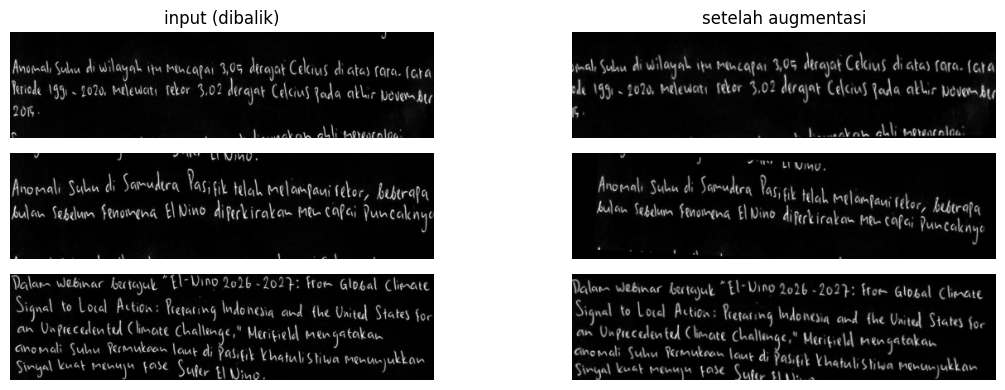

SimpleCNN  : 1,183,948 parameter
ResNet-18  : 11,199,084 parameter


In [8]:
torch.backends.cudnn.benchmark = True
X_dl = torch.from_numpy(255 - X_img).to(DEVICE)      # uint8 (N, H, W), tinta = terang, latar = 0
y_dl = torch.from_numpy(y).long().to(DEVICE)

def get_batch(idx):
    return X_dl[idx].unsqueeze(1).float() / 255.0, y_dl[idx]

def augment(x, max_deg=3, max_tx=0.03, max_ty=0.06, scale=(0.9, 1.05)):
    # random affine berbeda untuk setiap citra dalam batch
    B, _, H, W = x.shape
    rnd = lambda: torch.rand(B, device=x.device) * 2 - 1
    ang = rnd() * np.radians(max_deg)
    s = scale[0] + torch.rand(B, device=x.device) * (scale[1] - scale[0])
    cos, sin = torch.cos(ang) / s, torch.sin(ang) / s
    theta = torch.stack([torch.stack([cos, -sin * H / W, rnd() * max_tx * 2], 1),
                         torch.stack([sin * W / H, cos, rnd() * max_ty * 2], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

# contoh hasil augmentasi
xb, _ = get_batch(torch.arange(3, device=DEVICE))
xa = augment(xb)
fig, axes = plt.subplots(3, 2, figsize=(12, 4))
for i in range(3):
    axes[i, 0].imshow(xb[i, 0].cpu(), cmap="gray"); axes[i, 1].imshow(xa[i, 0].cpu(), cmap="gray")
    axes[i, 0].axis("off"); axes[i, 1].axis("off")
axes[0, 0].set_title("input (dibalik)"); axes[0, 1].set_title("setelah augmentasi"); plt.tight_layout(); plt.show()

class SimpleCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                                 nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, n_classes))
    def forward(self, x):
        return self.head(self.features(x))

class ResNet18TL(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        self.net.fc = nn.Linear(self.net.fc.in_features, n_classes)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return self.net((x.repeat(1, 3, 1, 1) - self.mean) / self.std)

n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"SimpleCNN  : {n_params(SimpleCNN(n_classes)):,} parameter")
print(f"ResNet-18  : {n_params(ResNet18TL(n_classes)):,} parameter")

In [9]:
def train_one_fold(make_model, tr, te, epochs, lr, batch_size=32, seed=SEED):
    set_seed(seed)
    model = make_model().to(DEVICE)
    tr, te = torch.as_tensor(tr, device=DEVICE), torch.as_tensor(te, device=DEVICE)
    steps = len(tr) // batch_size
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * steps, pct_start=0.15)
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))
    history = []

    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for ep in range(epochs):
        model.train(); total = torch.zeros((), device=DEVICE)
        perm = tr[torch.randperm(len(tr), device=DEVICE)]
        for b in range(steps):
            xb, yb = get_batch(perm[b * batch_size:(b + 1) * batch_size])
            xb = augment(xb)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, enabled=(DEVICE == "cuda")):
                loss = F.cross_entropy(model(xb), yb, label_smoothing=0.1)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            total += loss.detach()
        history.append(total.item() / steps)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t_train = time.perf_counter() - t0

    model.eval(); preds = []
    with torch.no_grad(), torch.autocast(device_type=DEVICE, enabled=(DEVICE == "cuda")):
        for b in range(0, len(te), 64):
            xb, _ = get_batch(te[b:b + 64])
            preds.append(model(xb).argmax(1).cpu())
    y_pred = torch.cat(preds).numpy()
    del model, opt; torch.cuda.empty_cache()
    return y_pred, t_train, history

def run_dl(make_model, name, epochs, lr):
    rows, histories = [], []
    for k, (tr, te) in enumerate(FOLDS, 1):
        y_pred, t_train, hist = train_one_fold(make_model, tr, te, epochs, lr, seed=SEED + k)
        res = evaluate(y[te], y_pred)
        res["Waktu Pelatihan (s)"] = t_train
        rows.append(res); histories.append(hist)
        print(f"[{name}] Eksperimen {k}: akurasi={res['Akurasi']:.4f}  F1={res['F1-Score']:.4f}  waktu={t_train:.1f}s  loss akhir={hist[-1]:.3f}")
    df = to_table(rows)
    ALL_RESULTS[name] = df
    df.to_csv(f"{RESULT_DIR}/{name.replace(' ', '_')}.csv")

    plt.figure(figsize=(6, 3))
    for k, h in enumerate(histories, 1): plt.plot(range(1, epochs + 1), h, label=f"Eksp {k}")
    plt.title(f"Training loss — {name}"); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.tight_layout(); plt.show()
    return df

### 8.1 Arsitektur Deep Learning 1 — CNN Sederhana (dari nol)

[CNN Sederhana] Eksperimen 1: akurasi=0.7451  F1=0.7504  waktu=233.4s  loss akhir=1.035


[CNN Sederhana] Eksperimen 2: akurasi=0.8268  F1=0.8251  waktu=214.9s  loss akhir=1.017


[CNN Sederhana] Eksperimen 3: akurasi=0.7749  F1=0.7790  waktu=213.9s  loss akhir=1.056


[CNN Sederhana] Eksperimen 4: akurasi=0.7641  F1=0.7709  waktu=213.8s  loss akhir=1.071


[CNN Sederhana] Eksperimen 5: akurasi=0.7554  F1=0.7575  waktu=218.8s  loss akhir=1.037


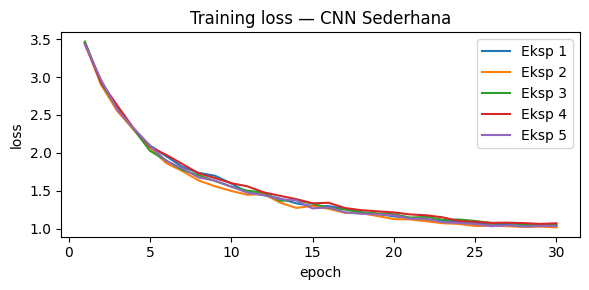

,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (s)
Eksperimen ke,,,,,
1,0.8425,0.7443,0.7451,0.7504,233.3707
2,0.8801,0.8244,0.8268,0.8251,214.9118
3,0.8575,0.7740,0.7749,0.7790,213.8742
4,0.8552,0.7615,0.7641,0.7709,213.8407
5,0.8381,0.7543,0.7554,0.7575,218.8182
Rata-Rata,0.8547,0.7717,0.7733,0.7766,218.9631


In [10]:
run_dl(lambda: SimpleCNN(n_classes), "CNN Sederhana", epochs=30, lr=2e-3)

### 8.2 Arsitektur Deep Learning 2 — ResNet-18 (Transfer Learning)

[ResNet-18] Eksperimen 1: akurasi=0.9914  F1=0.9914  waktu=117.4s  loss akhir=0.709


[ResNet-18] Eksperimen 2: akurasi=0.9827  F1=0.9819  waktu=110.8s  loss akhir=0.709


[ResNet-18] Eksperimen 3: akurasi=0.9870  F1=0.9868  waktu=107.2s  loss akhir=0.709


[ResNet-18] Eksperimen 4: akurasi=0.9870  F1=0.9870  waktu=107.2s  loss akhir=0.709


[ResNet-18] Eksperimen 5: akurasi=0.9870  F1=0.9868  waktu=107.4s  loss akhir=0.709


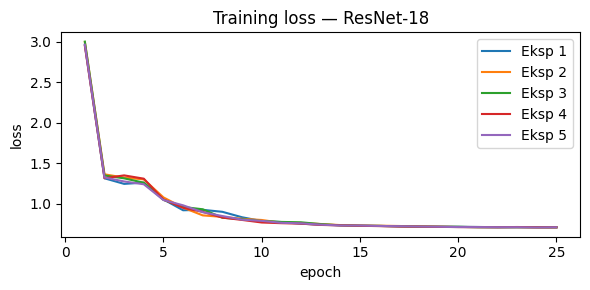

,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (s)
Eksperimen ke,,,,,
1,0.9921,0.9915,0.9914,0.9914,117.4473
2,0.9840,0.9818,0.9827,0.9819,110.7928
3,0.9877,0.9869,0.9870,0.9868,107.2465
4,0.9881,0.9869,0.9870,0.9870,107.1949
5,0.9882,0.9866,0.9870,0.9868,107.3787
Rata-Rata,0.9880,0.9868,0.9870,0.9868,110.0120


In [11]:
run_dl(lambda: ResNet18TL(n_classes), "ResNet-18", epochs=25, lr=1e-3)

## 9. Tabel Hasil per Metode

In [12]:
from IPython.display import display, Markdown
for name, df in ALL_RESULTS.items():
    display(Markdown(f"**{name}**"))
    display(df)

**SVM + GLCM**

,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (s)
Eksperimen ke,,,,,
1,0.8317,0.8148,0.8164,0.8107,0.0842
2,0.8013,0.7905,0.7944,0.7888,0.0844
3,0.8330,0.8167,0.8182,0.8181,0.0836
4,0.8157,0.7964,0.8009,0.7937,0.0824
5,0.7946,0.7797,0.7792,0.7770,0.0792
Rata-Rata,0.8153,0.7996,0.8018,0.7977,0.0828


**Random Forest + GLCM**

,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (s)
Eksperimen ke,,,,,
1,0.7406,0.7188,0.7214,0.7170,1.0058
2,0.7392,0.7273,0.7294,0.7252,0.9160
3,0.7547,0.7348,0.7359,0.7347,0.8861
4,0.7533,0.7265,0.7316,0.7238,0.9453
5,0.6913,0.6823,0.6840,0.6792,0.9771
Rata-Rata,0.7358,0.7179,0.7205,0.7160,0.9460


**CNN Sederhana**

,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (s)
Eksperimen ke,,,,,
1,0.8425,0.7443,0.7451,0.7504,233.3707
2,0.8801,0.8244,0.8268,0.8251,214.9118
3,0.8575,0.7740,0.7749,0.7790,213.8742
4,0.8552,0.7615,0.7641,0.7709,213.8407
5,0.8381,0.7543,0.7554,0.7575,218.8182
Rata-Rata,0.8547,0.7717,0.7733,0.7766,218.9631


**ResNet-18**

,Precision,Recall,Akurasi,F1-Score,Waktu Pelatihan (s)
Eksperimen ke,,,,,
1,0.9921,0.9915,0.9914,0.9914,117.4473
2,0.9840,0.9818,0.9827,0.9819,110.7928
3,0.9877,0.9869,0.9870,0.9868,107.2465
4,0.9881,0.9869,0.9870,0.9870,107.1949
5,0.9882,0.9866,0.9870,0.9868,107.3787
Rata-Rata,0.9880,0.9868,0.9870,0.9868,110.0120


## 10. Rekap Hasil Eksperimen

In [13]:
rekap = pd.DataFrame({name: df.loc["Rata-Rata"] for name, df in ALL_RESULTS.items()}).T
rekap.columns = ["Rata-Rata " + c for c in rekap.columns]
rekap.index.name = "Nama Algoritma"
rekap.to_csv(f"{RESULT_DIR}/rekap.csv")
print(f"Waktu preprocessing           : {t_prep:.2f} s")
print(f"Waktu ekstraksi fitur GLCM    : {t_glcm:.2f} s ({t_glcm / len(X_img) * 1000:.2f} ms/citra)")
rekap

Waktu preprocessing           : 7.83 s
Waktu ekstraksi fitur GLCM    : 5.20 s (2.25 ms/citra)


,Rata-Rata Precision,Rata-Rata Recall,Rata-Rata Akurasi,Rata-Rata F1-Score,Rata-Rata Waktu Pelatihan (s)
Nama Algoritma,,,,,
SVM + GLCM,0.8153,0.7996,0.8018,0.7977,0.0828
Random Forest + GLCM,0.7358,0.7179,0.7205,0.7160,0.9460
CNN Sederhana,0.8547,0.7717,0.7733,0.7766,218.9631
ResNet-18,0.9880,0.9868,0.9870,0.9868,110.0120


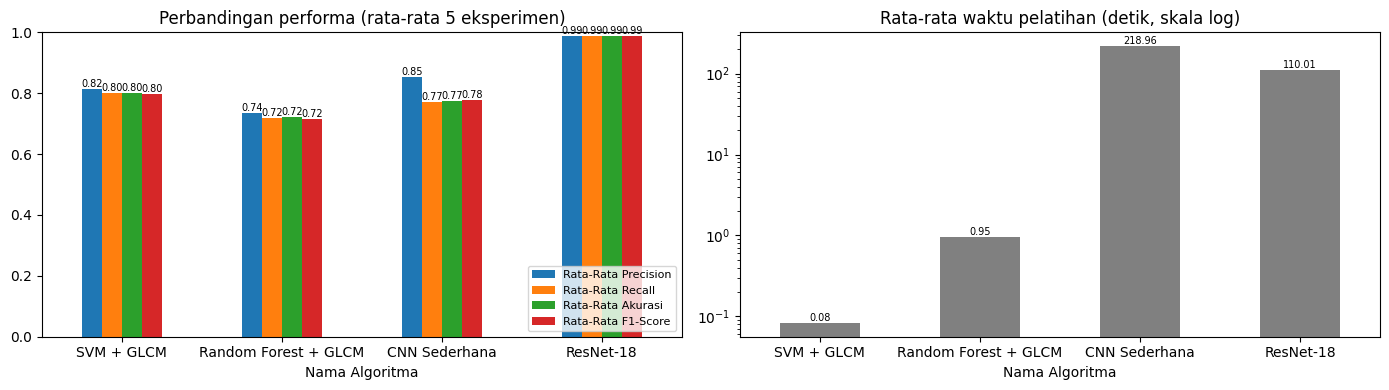

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
rekap.iloc[:, :4].plot(kind="bar", ax=axes[0], rot=0, ylim=(0, 1), title="Perbandingan performa (rata-rata 5 eksperimen)")
axes[0].legend(loc="lower right", fontsize=8)
rekap.iloc[:, 4].plot(kind="bar", ax=axes[1], rot=0, color="gray", logy=True, title="Rata-rata waktu pelatihan (detik, skala log)")
for ax in axes:
    for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7)
plt.tight_layout(); plt.savefig(f"{RESULT_DIR}/perbandingan.png", dpi=150); plt.show()

## 11. Kesimpulan

| Nama Algoritma | Precision | Recall | Akurasi | F1-Score | Waktu Pelatihan (s) |
|---|---|---|---|---|---|
| SVM + GLCM | 0.8153 | 0.7996 | 0.8018 | 0.7977 | 0.08 |
| Random Forest + GLCM | 0.7358 | 0.7179 | 0.7205 | 0.7160 | 0.95 |
| CNN Sederhana | 0.8547 | 0.7717 | 0.7733 | 0.7766 | 218.96 |
| **ResNet-18** | **0.9880** | **0.9868** | **0.9870** | **0.9868** | 110.01 |

Waktu ekstraksi fitur GLCM: **5,20 detik** untuk 2.311 citra (2,25 ms/citra).

1. **ResNet-18 (transfer learning)** memberikan hasil terbaik: akurasi rata-rata **98,70%**, stabil di 98,3–99,1% pada kelima eksperimen.
2. Di antara metode GLCM, **SVM** (80,18%) lebih baik dan lebih cepat daripada **Random Forest** (72,05%).
3. **CNN dari nol** (77,33%) masih kalah dari SVM + GLCM karena data latih (±42 citra per kelas) terlalu sedikit untuk melatih CNN dari nol. Bobot pra-latih ImageNet mengatasi masalah ini.
4. SVM + GLCM adalah pilihan praktis tanpa GPU (total ±5 detik), sedangkan ResNet-18 adalah pilihan bila akurasi yang diutamakan.

*Angka di atas berasal dari eksekusi notebook ini; nilai waktu dapat sedikit berbeda bila dijalankan ulang.*